# Projet SCI 1402 - Efficacité énergétique des véhicules au Canada

## Notebook 01 - Importation, exploration des données et modélisation initiale

**Source des données :** Ressources naturelles Canada (RNCan)  
**Période étudiée :** 2015 à 2024  

---

### Objectif du notebook

Ce premier notebook constitue la base du projet d'analyse de l'efficacité énergétique des véhicules au Canada.

Son objectif principal est d'importer, d'inspecter, de préparer et d'explorer les données de consommation de carburant publiées par Ressources naturelles Canada (RNCan), afin d'identifier les principales caractéristiques associées à la consommation combinée des véhicules.

Il vise également à développer et à évaluer les premiers modèles prédictifs permettant d'estimer la consommation combinée de carburant, exprimée en litres par 100 kilomètres (L/100 km), à partir des caractéristiques techniques des véhicules.

Les travaux réalisés dans ce notebook serviront de fondement aux analyses approfondies et aux validations effectuées dans les deux notebooks suivants.

### Méthodologie

L'analyse repose sur un jeu de données de 10 060 observations et de 15 variables couvrant les années modèles 2015 à 2024.

Les principales étapes comprennent :

  1. **Importation et inspection des données (M001 et suivantes)** : Chargement du fichier CSV, vérification de sa structure, identification des variables et examen des types de données.

  2. **Vérification de la qualité des données** : Recherche des valeurs manquantes, des doublons, des incohérences et des observations potentiellement aberrantes.

  3. **Préparation et normalisation** : Harmonisation des intitulés des catégories de véhicules et préparation des variables nécessaires aux analyses statistiques et prédictives.

  4. **Analyse exploratoire** : Étude des distributions de consommation, des caractéristiques techniques des véhicules, des différences entre catégories et de l'évolution des observations sur la période 2015–2024.

  5. **Analyse des relations entre variables** : Calcul de statistiques descriptives et de corrélations afin d'examiner les associations entre la cylindrée, le nombre de cylindres, la consommation combinée et les émissions de CO₂.

  6. **Sélection des variables explicatives** : Identification des caractéristiques pouvant être utilisées pour prédire la consommation combinée, en évitant l'utilisation de variables qui révéleraient directement la valeur à prédire.

  7. **Modélisation prédictive initiale** : Construction et comparaison de modèles de référence, notamment un modèle naïf, une régression linéaire et un modèle Random Forest.

  8. **Évaluation des performances** : Utilisation des indicateurs MAE, RMSE et R² pour comparer la précision des prédictions et sélectionner une approche de modélisation adaptée au projet.

### Variables utilisées pour la modélisation

La variable cible est la **consommation combinée de carburant (L/100 km)**.

Six variables explicatives sont retenues :

  - Année modèle
  - Cylindrée (L)
  - Nombre de cylindres
  - Catégorie de véhicule
  - Transmission
  - Type de carburant

Ces caractéristiques permettent de construire un modèle prédictif à partir des propriétés des véhicules, sans utiliser directement les autres mesures de consommation ou les émissions de CO₂ comme variables explicatives.

### Principaux résultats

L'analyse exploratoire met en évidence une relation importante entre la consommation combinée et certaines caractéristiques techniques des véhicules, particulièrement la cylindrée et le nombre de cylindres.

La consommation combinée moyenne de l'ensemble des observations est d'environ 10,98 L/100 km.

Les coefficients de corrélation de Pearson montrent notamment une association positive entre la cylindrée et la consommation combinée (r = 0,814), ainsi qu'entre le nombre de cylindres et la consommation combinée (r = 0,796).

La modélisation initiale permet également de constater que le Random Forest offre de meilleures performances prédictives que les modèles de référence évalués.

Ces premiers résultats justifient la poursuite de l'analyse avec une validation chronologique plus approfondie.

### Résultats produits

Ce notebook permet de produire :

  - Un jeu de données inspecté et préparé pour les analyses.
  - Des statistiques descriptives sur la consommation et les caractéristiques des véhicules.
  - Des tableaux et graphiques exploratoires.
  - Une matrice de corrélation entre les principales variables numériques.
  - Des modèles prédictifs initiaux et leurs indicateurs de performance.
  - Une première sélection du modèle à approfondir dans la suite du projet.

### Portée et limites

Les données représentent les configurations de véhicules répertoriées par Ressources naturelles Canada pour les années modèles 2015 à 2024. Elles ne constituent pas un échantillon représentatif des ventes de véhicules au Canada.

Les relations statistiques observées permettent d'identifier des associations entre les caractéristiques techniques et la consommation de carburant, mais ne démontrent pas de relations causales.

Les résultats de la modélisation initiale doivent également être interprétés selon le protocole d'évaluation utilisé.

Une validation chronologique complémentaire est donc réalisée dans le deuxième notebook afin de mieux évaluer la capacité du modèle à prédire la consommation de véhicules d'années plus récentes.

### Continuité du projet

Ce premier notebook constitue la première partie du développement technique du projet SCI 1402.

Les travaux se poursuivent dans :

  - **Notebook 02 - Modélisation et validation approfondie**  
  Analyse des résidus, évaluation des performances selon les caractéristiques des véhicules et validation chronologique.

  - **Notebook 03 - Analyses complémentaires et finalisation des résultats**  
  Étude approfondie des erreurs, consolidation des performances, production des figures définitives et exportation des résultats.

In [ ]:
# M001 - Vérification de l'environnement Python
# Objectif : Vérifier que Python fonctionne et identifier les
#            versions des bibliothèques utiles à mon projet.

import sys
import pandas as pd
import numpy as np
import matplotlib
import sklearn

print("Version de Python :", sys.version.split()[0])
print("Version de pandas :", pd.__version__)
print("Version de NumPy :", np.__version__)
print("Version de Matplotlib :", matplotlib.__version__)
print("Version de scikit-learn :", sklearn.__version__)

print("\nVérification terminée.")


Version de Python : 3.13.18
Version de pandas : 2.2.3
Version de NumPy : 2.4.6
Version de Matplotlib : 3.10.0
Version de scikit-learn : 1.6.1

Vérification terminée.


In [ ]:
# M002 - Téléchargement et inspection initiale du fichier source
# Objectif : Télécharger le CSV officiel et vérifier son contenu brut.
# Données : Aucune transformation des données n'est effectuée.

from pathlib import Path
import requests

url = (
    "https://open.canada.ca/data/dataset/"
    "98f1a129-f628-4ce4-b24d-6f16bf24dd64/"
    "resource/581ab81d-fe7f-4beb-9f31-e1b8e7552cb6/"
    "download/am2015-2024-cotes-de-consommation-de-carburant.csv"
)

dossier_source = Path("/content/data/raw")
dossier_source.mkdir(parents=True, exist_ok=True)

fichier_source = dossier_source / "am2015-2024-cotes-de-consommation-de-carburant.csv"

reponse = requests.get(url, timeout=60)
reponse.raise_for_status()

fichier_source.write_bytes(reponse.content)

print("Téléchargement réussi.")
print("Code HTTP :", reponse.status_code)
print("Taille du fichier :", len(reponse.content), "octets")
print("Nom du fichier :", fichier_source.name)

# Examiner les premières lignes sans encore interpréter le CSV.
print("\nPremières lignes du fichier brut :")

contenu = reponse.content.decode("utf-8-sig", errors="replace")
for numero, ligne in enumerate(contenu.splitlines()[:5], start=1):
    print(f"{numero}: {ligne[:500]}")


Téléchargement réussi.
Code HTTP : 200
Taille du fichier : 864475 octets
Nom du fichier : am2015-2024-cotes-de-consommation-de-carburant.csv

Premières lignes du fichier brut :
1: Ann�e mod�le,Marque,Mod�le,Cat�gorie de v�hicule,Cylindr�e (L),Cylindres,Transmission,Type de carburant,Ville (L/100 km),Route (L/100 km),Combin�e (L/100 km),Combin�e (mi/gal),�missions de CO2 (g/km),Indice de CO2,Indice de smog
2: 2015,Acura,ILX,Compacte,2.0,4,AS5,Z,9.7,6.7,8.3,34,191,s.o.,s.o.
3: 2015,Acura,ILX,Compacte,2.4,4,M6,Z,10.8,7.4,9.3,30,214,s.o.,s.o.
4: 2015,Acura,ILX Hybrid,Compacte,1.5,4,AV7,Z,6.0,6.1,6.1,46,140,s.o.,s.o.
5: 2015,Acura,MDX SH-AWD,V�hicule utilitaire sport : petit,3.5,6,AS6,Z,12.7,9.1,11.1,25,255,s.o.,s.o.


In [ ]:
# M003 - Importation et inspection structurelle
# Objectif : Vérifier l'encodage, les dimensions et la qualité initiale.
# Données : Le fichier source reste inchangé.

import pandas as pd

encodages_a_tester = ["utf-8-sig", "cp1252"]
df = None
encodage_utilise = None

for encodage in encodages_a_tester:
    try:
        df = pd.read_csv(fichier_source, encoding=encodage)
        encodage_utilise = encodage
        break
    except UnicodeDecodeError:
        print(f"Encodage {encodage} : échec du décodage.")

if df is None:
    raise ValueError("Impossible de lire le fichier avec les encodages testés.")

print("Encodage utilisé :", encodage_utilise)
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

print("\nNoms des colonnes :")
for colonne in df.columns:
    print("-", colonne)

print("\nAperçu des 5 premières lignes :")
display(df.head())

print("\nTypes de données :")
print(df.dtypes)

print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

print("\nNombre de lignes entièrement dupliquées :")
print(df.duplicated().sum())

print("\nNombre de cellules contenant exactement 's.o.' par colonne :")
print(df.astype("string").eq("s.o.").sum())


Encodage utf-8-sig : échec du décodage.
Encodage utilisé : cp1252
Nombre de lignes : 10060
Nombre de colonnes : 15

Noms des colonnes :
- Année modèle
- Marque
- Modèle
- Catégorie de véhicule
- Cylindrée (L)
- Cylindres
- Transmission
- Type de carburant
- Ville (L/100 km)
- Route (L/100 km)
- Combinée (L/100 km)
- Combinée (mi/gal)
- Émissions de CO2 (g/km)
- Indice de CO2
- Indice de smog

Aperçu des 5 premières lignes :


,Année modèle,Marque,Modèle,Catégorie de véhicule,Cylindrée (L),Cylindres,Transmission,Type de carburant,Ville (L/100 km),Route (L/100 km),Combinée (L/100 km),Combinée (mi/gal),Émissions de CO2 (g/km),Indice de CO2,Indice de smog
0,2015,Acura,ILX,Compacte,2.0,4,AS5,Z,9.7,6.7,8.3,34,191,s.o.,s.o.
1,2015,Acura,ILX,Compacte,2.4,4,M6,Z,10.8,7.4,9.3,30,214,s.o.,s.o.
2,2015,Acura,ILX Hybrid,Compacte,1.5,4,AV7,Z,6.0,6.1,6.1,46,140,s.o.,s.o.
3,2015,Acura,MDX SH-AWD,Véhicule utilitaire sport : petit,3.5,6,AS6,Z,12.7,9.1,11.1,25,255,s.o.,s.o.
4,2015,Acura,RDX AWD,Véhicule utilitaire sport : petit,3.5,6,AS6,Z,12.1,8.7,10.6,27,244,s.o.,s.o.



Types de données :
Année modèle                 int64
Marque                      object
Modèle                      object
Catégorie de véhicule       object
Cylindrée (L)              float64
Cylindres                    int64
Transmission                object
Type de carburant           object
Ville (L/100 km)           float64
Route (L/100 km)           float64
Combinée (L/100 km)        float64
Combinée (mi/gal)            int64
Émissions de CO2 (g/km)      int64
Indice de CO2               object
Indice de smog              object
dtype: object

Valeurs manquantes par colonne :
Année modèle               0
Marque                     0
Modèle                     0
Catégorie de véhicule      0
Cylindrée (L)              0
Cylindres                  0
Transmission               0
Type de carburant          0
Ville (L/100 km)           0
Route (L/100 km)           0
Combinée (L/100 km)        0
Combinée (mi/gal)          0
Émissions de CO2 (g/km)    0
Indice de CO2              0
I

In [ ]:
# M004 - Analyse des valeurs spéciales
# Objectif : Déterminer où apparaissent les mentions "s.o."
#            et vérifier la couverture temporelle des données.
# Données : Aucune valeur n'est supprimée ou remplacée.

colonnes_indices = ["Indice de CO2", "Indice de smog"]

print("ANNÉES COUVERTES")
print("Première année :", df["Année modèle"].min())
print("Dernière année :", df["Année modèle"].max())
print("\nNombre d'observations par année :")
print(df["Année modèle"].value_counts().sort_index())

print("\nMENTIONS 's.o.' PAR ANNÉE")
for colonne in colonnes_indices:
    indicateur = df[colonne].astype("string").str.strip().eq("s.o.")

    resultat = (
        df.assign(mention_so=indicateur)
          .groupby("Année modèle")["mention_so"]
          .agg(["sum", "count"])
    )

    resultat["proportion_so_pct"] = (
        100 * resultat["sum"] / resultat["count"]
    ).round(1)

    print(f"\n{colonne} :")
    display(resultat.rename(columns={
        "sum": "Nombre de s.o.",
        "count": "Nombre de lignes",
        "proportion_so_pct": "Proportion de s.o. (%)"
    }))

print("\nVALEURS DISTINCTES DES INDICES")
for colonne in colonnes_indices:
    valeurs = df[colonne].astype("string").str.strip()
    valeurs_hors_so = valeurs[valeurs.ne("s.o.")].dropna().unique()

    print(f"\n{colonne}")
    print("Nombre de valeurs distinctes hors s.o. :",
          len(valeurs_hors_so))
    print("Quelques valeurs observées :",
          sorted(valeurs_hors_so.tolist())[:20])


ANNÉES COUVERTES
Première année : 2015
Dernière année : 2024

Nombre d'observations par année :
Année modèle
2015    1128
2016    1106
2017    1058
2018    1083
2019    1056
2020     975
2021     970
2022     976
2023     919
2024     789
Name: count, dtype: int64

MENTIONS 's.o.' PAR ANNÉE

Indice de CO2 :


,Nombre de s.o.,Nombre de lignes,Proportion de s.o. (%)
Année modèle,,,
2015,1128,1128,100.0
2016,0,1106,0.0
2017,0,1058,0.0
2018,0,1083,0.0
2019,0,1056,0.0
2020,0,975,0.0
2021,0,970,0.0
2022,0,976,0.0
2023,0,919,0.0



Indice de smog :


,Nombre de s.o.,Nombre de lignes,Proportion de s.o. (%)
Année modèle,,,
2015,1128,1128,100.0
2016,1106,1106,100.0
2017,0,1058,0.0
2018,0,1083,0.0
2019,0,1056,0.0
2020,0,975,0.0
2021,0,970,0.0
2022,0,976,0.0
2023,0,919,0.0



VALEURS DISTINCTES DES INDICES

Indice de CO2
Nombre de valeurs distinctes hors s.o. : 10
Quelques valeurs observées : ['1', '10', '2', '3', '4', '5', '6', '7', '8', '9']

Indice de smog
Nombre de valeurs distinctes hors s.o. : 7
Quelques valeurs observées : ['1', '2', '3', '5', '6', '7', '8']


In [ ]:
# M005 - Contrôle de cohérence des variables numériques
# Objectif : Examiner les plages de valeurs et repérer les anomalies potentielles.
# Données : Aucune ligne ni aucune valeur n'est modifiée.

variables_numeriques = [
    "Année modèle",
    "Cylindrée (L)",
    "Cylindres",
    "Ville (L/100 km)",
    "Route (L/100 km)",
    "Combinée (L/100 km)",
    "Combinée (mi/gal)",
    "Émissions de CO2 (g/km)"
]

print("1. STATISTIQUES DESCRIPTIVES")
display(df[variables_numeriques].describe().T)

print("\n2. VALEURS NULLES OU NÉGATIVES")

variables_strictement_positives = [
    "Cylindrée (L)",
    "Cylindres",
    "Ville (L/100 km)",
    "Route (L/100 km)",
    "Combinée (L/100 km)",
    "Combinée (mi/gal)",
    "Émissions de CO2 (g/km)"
]

for colonne in variables_strictement_positives:
    valeurs = df[colonne]
    print(
        f"{colonne} : "
        f"zéro = {(valeurs == 0).sum()}, "
        f"négatives = {(valeurs < 0).sum()}"
    )

print("\n3. VALEURS DISTINCTES DES VARIABLES CATÉGORIELLES")
variables_categorielles = [
    "Catégorie de véhicule",
    "Type de carburant",
    "Transmission"
]

for colonne in variables_categorielles:
    print(f"\n{colonne} : {df[colonne].nunique()} valeurs distinctes")
    print(df[colonne].value_counts().to_string())

print("\n4. VALEURS DISTINCTES DES INDICES")
for colonne in ["Indice de CO2", "Indice de smog"]:
    print(f"\n{colonne} :")
    print(df[colonne].value_counts(dropna=False).sort_index().to_string())


1. STATISTIQUES DESCRIPTIVES


,count,mean,std,min,25%,50%,75%,max
Année modèle,10060.0,2019.242048,2.834109,2015.0,2017.0,2019.0,2022.0,2024.0
Cylindrée (L),10060.0,3.144901,1.340010,0.9,2.0,3.0,3.7,8.4
Cylindres,10060.0,5.618390,1.875910,3.0,4.0,6.0,6.0,16.0
Ville (L/100 km),10060.0,12.483052,3.404483,4.0,10.1,12.1,14.5,30.7
Route (L/100 km),10060.0,9.142803,2.178649,3.9,7.6,8.9,10.4,20.9
Combinée (L/100 km),10060.0,10.979712,2.808468,4.0,9.0,10.7,12.7,26.1
Combinée (mi/gal),10060.0,27.436282,7.316270,11.0,22.0,26.0,31.0,71.0
Émissions de CO2 (g/km),10060.0,253.711332,60.474917,94.0,210.0,250.0,292.0,608.0



2. VALEURS NULLES OU NÉGATIVES
Cylindrée (L) : zéro = 0, négatives = 0
Cylindres : zéro = 0, négatives = 0
Ville (L/100 km) : zéro = 0, négatives = 0
Route (L/100 km) : zéro = 0, négatives = 0
Combinée (L/100 km) : zéro = 0, négatives = 0
Combinée (mi/gal) : zéro = 0, négatives = 0
Émissions de CO2 (g/km) : zéro = 0, négatives = 0

3. VALEURS DISTINCTES DES VARIABLES CATÉGORIELLES

Catégorie de véhicule : 17 valeurs distinctes
Catégorie de véhicule
Véhicule utilitaire sport : petit        1870
Intermédiaire                            1393
Véhicule utilitaire sport : ordinaire    1229
Compacte                                 1134
Camionnette : ordinaire                   878
Sous-compacte                             850
Grande berline                            779
Deux places                               639
Minicompacte                              460
Familiale : petite                        282
Camionnette : petite                      220
Fourgonnette                            

In [ ]:
# M006 - Inspection des catégories rares et cohérence des consommations
# Objectif : Repérer les observations nécessitant une vérification.
# Données : Aucune valeur n'est modifiée et aucune ligne n'est supprimée.

import pandas as pd

print("1. CATÉGORIES DE VÉHICULE RARES")

frequence_categories = df["Catégorie de véhicule"].value_counts()
categories_rares = frequence_categories[frequence_categories <= 5]

display(categories_rares)

print("\nLIGNES CORRESPONDANT AUX CATÉGORIES RARES")
display(
    df[df["Catégorie de véhicule"].isin(categories_rares.index)]
)

print("\n2. CARBURANTS RARES")

frequence_carburants = df["Type de carburant"].value_counts()
carburants_rares = frequence_carburants[frequence_carburants <= 5]

display(carburants_rares)

display(
    df[df["Type de carburant"].isin(carburants_rares.index)]
)

print("\n3. CONSOMMATION COMBINÉE HORS DE L'INTERVALLE")

# Une consommation combinée est normalement comprise entre
# les consommations en ville et sur route.

ville = df["Ville (L/100 km)"]
route = df["Route (L/100 km)"]
combinee = df["Combinée (L/100 km)"]

# Calcul des bornes pour chaque observation.
borne_basse = pd.concat([ville, route], axis=1).min(axis=1)
borne_haute = pd.concat([ville, route], axis=1).max(axis=1)

# Repérage des observations hors intervalle.
hors_intervalle = (
    (combinee < borne_basse) |
    (combinee > borne_haute)
)

print("Nombre de lignes hors intervalle :", int(hors_intervalle.sum()))
print("Nombre de lignes dans l'intervalle :", int((~hors_intervalle).sum()))

display(
    df.loc[
        hors_intervalle,
        [
            "Année modèle",
            "Marque",
            "Modèle",
            "Ville (L/100 km)",
            "Route (L/100 km)",
            "Combinée (L/100 km)"
        ]
    ].head(20)
)

print("\n4. INDICES : VALEURS DISTINCTES NUMÉRIQUES")

for colonne in ["Indice de CO2", "Indice de smog"]:

    valeurs = df.loc[df[colonne] != "s.o.", colonne]
    valeurs_numeriques = pd.to_numeric(valeurs, errors="coerce")

    print(f"\n{colonne}")
    print(
        "Valeurs numériques distinctes :",
        sorted(valeurs_numeriques.dropna().unique().tolist())
    )
    print(
        "Valeurs non convertibles, hors s.o. :",
        int(valeurs_numeriques.isna().sum())
    )

print("\nM006 - Vérification terminée.")


1. CATÉGORIES DE VÉHICULE RARES


,count
Catégorie de véhicule,
Compact,1



LIGNES CORRESPONDANT AUX CATÉGORIES RARES


,Année modèle,Marque,Modèle,Catégorie de véhicule,Cylindrée (L),Cylindres,Transmission,Type de carburant,Ville (L/100 km),Route (L/100 km),Combinée (L/100 km),Combinée (mi/gal),Émissions de CO2 (g/km),Indice de CO2,Indice de smog
5942,2020,Jaguar,XE P250,Compact,2.0,4,AS8,Z,9.4,7.0,8.3,34,194,6,7



2. CARBURANTS RARES


,count
Type de carburant,
N,1


,Année modèle,Marque,Modèle,Catégorie de véhicule,Cylindrée (L),Cylindres,Transmission,Type de carburant,Ville (L/100 km),Route (L/100 km),Combinée (L/100 km),Combinée (mi/gal),Émissions de CO2 (g/km),Indice de CO2,Indice de smog
1364,2016,Chevrolet,Impala Dual Fuel,Intermédiaire,3.6,6,AS6,N,15.2,9.5,12.7,22,213,6,s.o.



3. CONSOMMATION COMBINÉE HORS DE L'INTERVALLE
Nombre de lignes hors intervalle : 0
Nombre de lignes dans l'intervalle : 10060


,Année modèle,Marque,Modèle,Ville (L/100 km),Route (L/100 km),Combinée (L/100 km)



4. INDICES : VALEURS DISTINCTES NUMÉRIQUES

Indice de CO2
Valeurs numériques distinctes : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Valeurs non convertibles, hors s.o. : 0

Indice de smog
Valeurs numériques distinctes : [1, 2, 3, 5, 6, 7, 8]
Valeurs non convertibles, hors s.o. : 0

M006 - Vérification terminée.


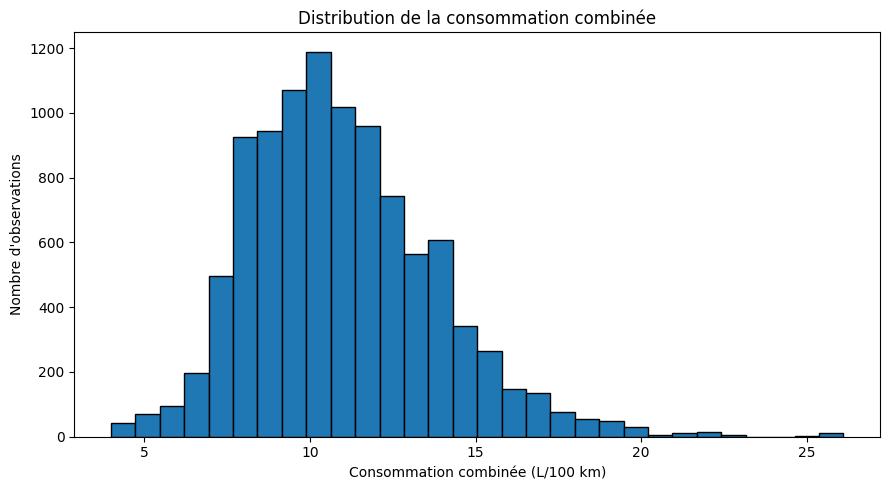

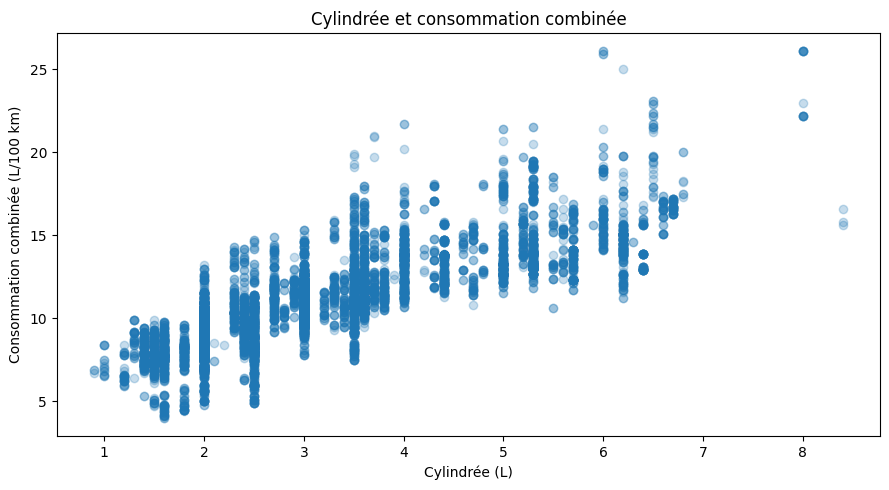

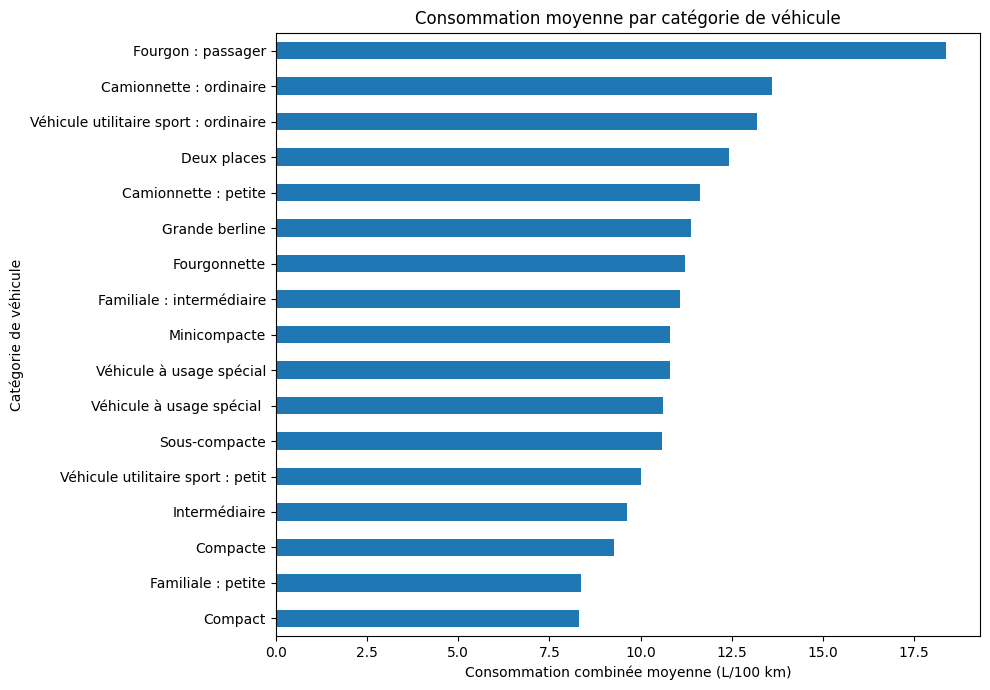

Moyenne générale : 10.98 L/100 km
Médiane générale : 10.7 L/100 km

Moyenne par catégorie :


,Consommation moyenne (L/100 km)
Catégorie de véhicule,
Compact,8.30
Familiale : petite,8.37
Compacte,9.27
Intermédiaire,9.63
Véhicule utilitaire sport : petit,10.02
Sous-compacte,10.59
Véhicule à usage spécial,10.62
Véhicule à usage spécial,10.81
Minicompacte,10.81


In [ ]:
# M007 - Première analyse exploratoire
# Objectif : Explorer la distribution de la consommation
#            et ses relations avec deux caractéristiques des véhicules.
# Données : Les données originales ne sont pas modifiées.

import matplotlib.pyplot as plt

# 1. Graphique de distribution de la consommation combinée.
plt.figure(figsize=(9, 5))
plt.hist(df["Combinée (L/100 km)"], bins=30, edgecolor="black")
plt.xlabel("Consommation combinée (L/100 km)")
plt.ylabel("Nombre d'observations")
plt.title("Distribution de la consommation combinée")
plt.tight_layout()
plt.show()

# 2. Graphique de cylindrée et consommation combinée.
plt.figure(figsize=(9, 5))
plt.scatter(
    df["Cylindrée (L)"],
    df["Combinée (L/100 km)"],
    alpha=0.25
)
plt.xlabel("Cylindrée (L)")
plt.ylabel("Consommation combinée (L/100 km)")
plt.title("Cylindrée et consommation combinée")
plt.tight_layout()
plt.show()

# 3. Graphique de consommation moyenne par catégorie de véhicule.
moyennes_categories = (
    df.groupby("Catégorie de véhicule")["Combinée (L/100 km)"]
      .mean()
      .sort_values()
)

plt.figure(figsize=(10, 7))
moyennes_categories.plot(kind="barh")
plt.xlabel("Consommation combinée moyenne (L/100 km)")
plt.ylabel("Catégorie de véhicule")
plt.title("Consommation moyenne par catégorie de véhicule")
plt.tight_layout()
plt.show()

# Statistiques utiles pour interpréter les graphiques.
print("Moyenne générale :",
      round(df["Combinée (L/100 km)"].mean(), 2), "L/100 km")

print("Médiane générale :",
      round(df["Combinée (L/100 km)"].median(), 2), "L/100 km")

print("\nMoyenne par catégorie :")
display(
    moyennes_categories.round(2).rename(
        "Consommation moyenne (L/100 km)"
    ).to_frame()
)


In [ ]:
# M008 - Vérification des libellés des catégories
# Objectif : Repérer les espaces ou caractères invisibles.
# Données : Aucune modification du jeu de données n'est effectuée.

colonne = "Catégorie de véhicule"

print("Libellés exacts et effectifs :")

for libelle in sorted(df[colonne].dropna().unique(), key=str):
    masque = df[colonne].eq(libelle)
    print(
        f"{repr(libelle)} | "
        f"Effectif : {masque.sum()} | "
        f"Moyenne : "
        f"{df.loc[masque, 'Combinée (L/100 km)'].mean():.2f} L/100 km"
    )

print("\nNombre de libellés distincts :", df[colonne].nunique())
print(
    "Nombre de libellés ayant des espaces superflus :",
    df[colonne].ne(df[colonne].str.strip()).sum()
)


Libellés exacts et effectifs :
'Camionnette : ordinaire' | Effectif : 878 | Moyenne : 13.61 L/100 km
'Camionnette : petite' | Effectif : 220 | Moyenne : 11.64 L/100 km
'Compact' | Effectif : 1 | Moyenne : 8.30 L/100 km
'Compacte' | Effectif : 1134 | Moyenne : 9.27 L/100 km
'Deux places' | Effectif : 639 | Moyenne : 12.43 L/100 km
'Familiale : intermédiaire' | Effectif : 82 | Moyenne : 11.07 L/100 km
'Familiale : petite' | Effectif : 282 | Moyenne : 8.37 L/100 km
'Fourgon : passager' | Effectif : 45 | Moyenne : 18.38 L/100 km
'Fourgonnette' | Effectif : 95 | Moyenne : 11.21 L/100 km
'Grande berline' | Effectif : 779 | Moyenne : 11.39 L/100 km
'Intermédiaire' | Effectif : 1393 | Moyenne : 9.63 L/100 km
'Minicompacte' | Effectif : 460 | Moyenne : 10.81 L/100 km
'Sous-compacte' | Effectif : 850 | Moyenne : 10.59 L/100 km
'Véhicule utilitaire sport : ordinaire' | Effectif : 1229 | Moyenne : 13.19 L/100 km
'Véhicule utilitaire sport : petit' | Effectif : 1870 | Moyenne : 10.02 L/100 km
'Véhi

In [ ]:
# M009 - Vérification avant normalisation des catégories
# Données : Le DataFrame df original demeure inchangé.

colonne = "Catégorie de véhicule"

# Afficher les lignes avec espaces superflus.
masque_espaces = df[colonne].ne(df[colonne].str.strip())

print("Lignes avec espaces superflus :")
display(
    df.loc[masque_espaces, [
        "Année modèle", "Marque", "Modèle", colonne
    ]]
)

# Examiner séparément la catégorie rare « Compact ».
print("\nLigne classée « Compact » :")
display(
    df.loc[df[colonne].eq("Compact"), [
        "Année modèle", "Marque", "Modèle",
        colonne, "Cylindrée (L)", "Combinée (L/100 km)"
    ]]
)

# Simulation : Normaliser les espaces dans une copie seulement.
df_test = df.copy()
df_test[colonne] = df_test[colonne].str.strip()

print("\nNombre de catégories avant :", df[colonne].nunique())
print("Nombre de catégories après suppression des espaces :",
      df_test[colonne].nunique())

print("\nEffectifs des catégories concernées après simulation :")
display(
    df_test[colonne].value_counts().to_frame("Effectif")
    .loc[lambda t: t.index.isin([
        "Véhicule à usage spécial", "Compact", "Compacte"
    ])]
)


Lignes avec espaces superflus :


,Année modèle,Marque,Modèle,Catégorie de véhicule
6757,2021,Ford,Transit Connect Van,Véhicule à usage spécial
6758,2021,Ford,Transit Connect Van FFV,Véhicule à usage spécial
6759,2021,Ford,Transit Connect Van FFV,Véhicule à usage spécial
6760,2021,Ford,Transit Connect Van,Véhicule à usage spécial
6761,2021,Ford,Transit Connect Wagon LWB,Véhicule à usage spécial
6762,2021,Ford,Transit Connect Wagon LWB FFV,Véhicule à usage spécial
6763,2021,Ford,Transit Connect Wagon LWB FFV,Véhicule à usage spécial
6764,2021,Ford,Transit Connect Wagon LWB,Véhicule à usage spécial
7137,2021,Mercedes-Benz,Metris Cargo Van,Véhicule à usage spécial
7138,2021,Mercedes-Benz,Metris Cargo Van LWB,Véhicule à usage spécial



Ligne classée « Compact » :


,Année modèle,Marque,Modèle,Catégorie de véhicule,Cylindrée (L),Combinée (L/100 km)
5942,2020,Jaguar,XE P250,Compact,2.0,8.3



Nombre de catégories avant : 17
Nombre de catégories après suppression des espaces : 16

Effectifs des catégories concernées après simulation :


,Effectif
Catégorie de véhicule,
Compacte,1134
Véhicule à usage spécial,103
Compact,1


In [ ]:
# M010 - Normalisation des espaces dans les catégories
# Données : df reste inchangé ; toutes les modifications sont faites dans une copie.

df_analyse = df.copy()

colonne = "Catégorie de véhicule"
categories_avant = df_analyse[colonne].nunique()
lignes_corrigees = int(
    df_analyse[colonne].ne(df_analyse[colonne].str.strip()).sum()
)

# Normaliser les espaces au début et à la fin des libellés.
df_analyse[colonne] = df_analyse[colonne].str.strip()

print("Lignes dont le libellé a été corrigé :", lignes_corrigees)
print("Catégories avant :", categories_avant)
print("Catégories après :", df_analyse[colonne].nunique())
print("Nombre de lignes avant :", len(df))
print("Nombre de lignes après :", len(df_analyse))
print("df original toujours inchangé :",
      df[colonne].nunique() == categories_avant)

print("\nEffectifs des catégories concernées :")
display(
    df_analyse[colonne]
    .value_counts()
    .reindex(["Véhicule à usage spécial", "Compact", "Compacte"])
    .to_frame("Effectif")
)

print("\nDoublons exacts dans la copie après normalisation :",
      df_analyse.duplicated().sum())


Lignes dont le libellé a été corrigé : 13
Catégories avant : 17
Catégories après : 16
Nombre de lignes avant : 10060
Nombre de lignes après : 10060
df original toujours inchangé : True

Effectifs des catégories concernées :


,Effectif
Catégorie de véhicule,
Véhicule à usage spécial,103
Compact,1
Compacte,1134



Doublons exacts dans la copie après normalisation : 0


In [ ]:
# M011 - Statistiques descriptives après normalisation
# Objectif : Établir les statistiques de référence pour la suite du projet.
# Entrée : df_analyse, copie de travail normalisée.
# Données : Aucune modification des valeurs n'est effectuée.

import pandas as pd

print("Dimensions du jeu de données :", df_analyse.shape)

print("\nStatistiques de consommation et variables numériques :")
display(
    df_analyse[
        [
            "Cylindrée (L)",
            "Cylindres",
            "Ville (L/100 km)",
            "Route (L/100 km)",
            "Combinée (L/100 km)",
            "Émissions de CO2 (g/km)"
        ]
    ].describe().round(2)
)

print("\nConsommation combinée par catégorie :")
resume_categories = (
    df_analyse.groupby("Catégorie de véhicule")["Combinée (L/100 km)"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean")
)

display(
    resume_categories.rename(columns={
        "count": "Effectif",
        "mean": "Moyenne (L/100 km)",
        "median": "Médiane (L/100 km)",
        "std": "Écart-type"
    })
)

print("\nConsommation moyenne générale :",
      round(df_analyse["Combinée (L/100 km)"].mean(), 2),
      "L/100 km")

print("Consommation médiane générale :",
      round(df_analyse["Combinée (L/100 km)"].median(), 2),
      "L/100 km")


Dimensions du jeu de données : (10060, 15)

Statistiques de consommation et variables numériques :


,Cylindrée (L),Cylindres,Ville (L/100 km),Route (L/100 km),Combinée (L/100 km),Émissions de CO2 (g/km)
count,10060.00,10060.00,10060.00,10060.00,10060.00,10060.00
mean,3.14,5.62,12.48,9.14,10.98,253.71
std,1.34,1.88,3.40,2.18,2.81,60.47
min,0.90,3.00,4.00,3.90,4.00,94.00
25%,2.00,4.00,10.10,7.60,9.00,210.00
50%,3.00,6.00,12.10,8.90,10.70,250.00
75%,3.70,6.00,14.50,10.40,12.70,292.00
max,8.40,16.00,30.70,20.90,26.10,608.00



Consommation combinée par catégorie :


,Effectif,Moyenne (L/100 km),Médiane (L/100 km),Écart-type
Catégorie de véhicule,,,,
Compact,1,8.30,8.3,NaN
Familiale : petite,282,8.37,8.5,1.36
Compacte,1134,9.27,8.9,2.20
Intermédiaire,1393,9.63,9.1,2.59
Véhicule utilitaire sport : petit,1870,10.02,9.9,1.64
Sous-compacte,850,10.59,10.3,2.10
Véhicule à usage spécial,103,10.78,10.5,1.50
Minicompacte,460,10.81,11.0,1.91
Familiale : intermédiaire,82,11.07,10.2,2.70



Consommation moyenne générale : 10.98 L/100 km
Consommation médiane générale : 10.7 L/100 km


Matrice de corrélation de Pearson :


,Cylindrée (L),Cylindres,Combinée (L/100 km),Émissions de CO2 (g/km)
Cylindrée (L),1.000,0.923,0.814,0.828
Cylindres,0.923,1.000,0.796,0.824
Combinée (L/100 km),0.814,0.796,1.000,0.945
Émissions de CO2 (g/km),0.828,0.824,0.945,1.000


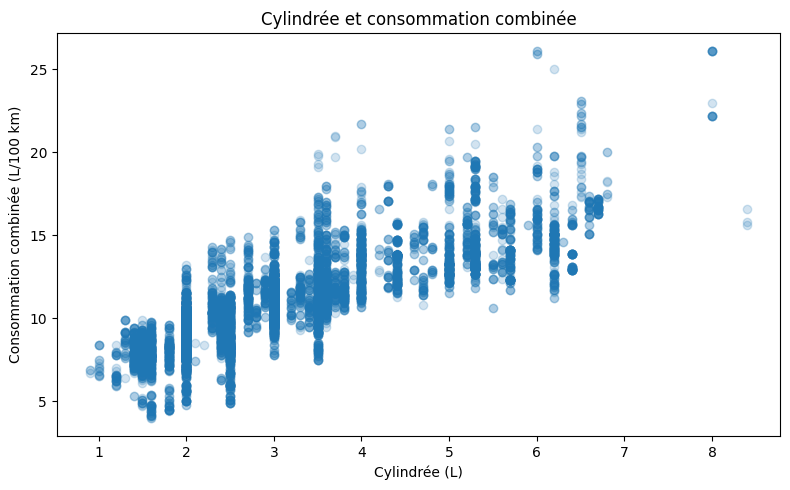

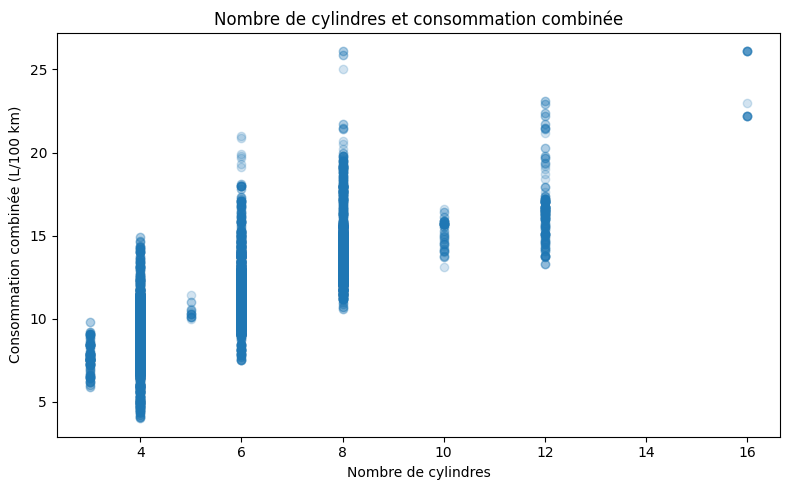

Consommation selon le code de carburant :


,Effectif,Moyenne (L/100 km),Médiane (L/100 km),Écart-type
Type de carburant,,,,
D,236,9.34,9.8,1.43
X,4756,10.06,9.8,2.48
Z,4739,11.60,11.2,2.54
N,1,12.70,12.7,NaN
E,328,16.63,17.1,2.57


In [ ]:
# M012 - Relations exploratoires avec la consommation
# Entrée : df_analyse
# Objectif : Examiner des associations, sans prétendre établir de causalité.
# Données : Aucune modification du jeu de données.

import matplotlib.pyplot as plt

# 1. Corrélations entre les variables numériques sélectionnées.
variables = [
    "Cylindrée (L)",
    "Cylindres",
    "Combinée (L/100 km)",
    "Émissions de CO2 (g/km)"
]

correlations = df_analyse[variables].corr().round(3)

print("Matrice de corrélation de Pearson :")
display(correlations)

# 2. Cylindrée et consommation combinée.
plt.figure(figsize=(8, 5))
plt.scatter(
    df_analyse["Cylindrée (L)"],
    df_analyse["Combinée (L/100 km)"],
    alpha=0.2
)
plt.xlabel("Cylindrée (L)")
plt.ylabel("Consommation combinée (L/100 km)")
plt.title("Cylindrée et consommation combinée")
plt.tight_layout()
plt.show()

# 3. Nombre de cylindres et consommation combinée.
plt.figure(figsize=(8, 5))
plt.scatter(
    df_analyse["Cylindres"],
    df_analyse["Combinée (L/100 km)"],
    alpha=0.2
)
plt.xlabel("Nombre de cylindres")
plt.ylabel("Consommation combinée (L/100 km)")
plt.title("Nombre de cylindres et consommation combinée")
plt.tight_layout()
plt.show()

# 4. Consommation moyenne et effectif par type de carburant.
resume_carburant = (
    df_analyse.groupby("Type de carburant")["Combinée (L/100 km)"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("mean")
)

print("Consommation selon le code de carburant :")
display(
    resume_carburant.rename(columns={
        "count": "Effectif",
        "mean": "Moyenne (L/100 km)",
        "median": "Médiane (L/100 km)",
        "std": "Écart-type"
    })
)


Résumé annuel :


,Effectif,Moyenne,Mediane,Ecart_type,CO2_moyen
Année modèle,,,,,
2015,1128,10.98,10.5,2.99,246.88
2016,1106,10.81,10.5,2.69,248.08
2017,1058,10.87,10.4,2.76,249.93
2018,1083,10.85,10.5,2.69,250.05
2019,1056,10.87,10.6,2.70,251.29
2020,975,10.97,10.7,2.80,254.80
2021,970,11.10,10.8,2.89,259.66
2022,976,11.15,10.9,2.88,260.49
2023,919,11.19,11.0,2.84,260.41


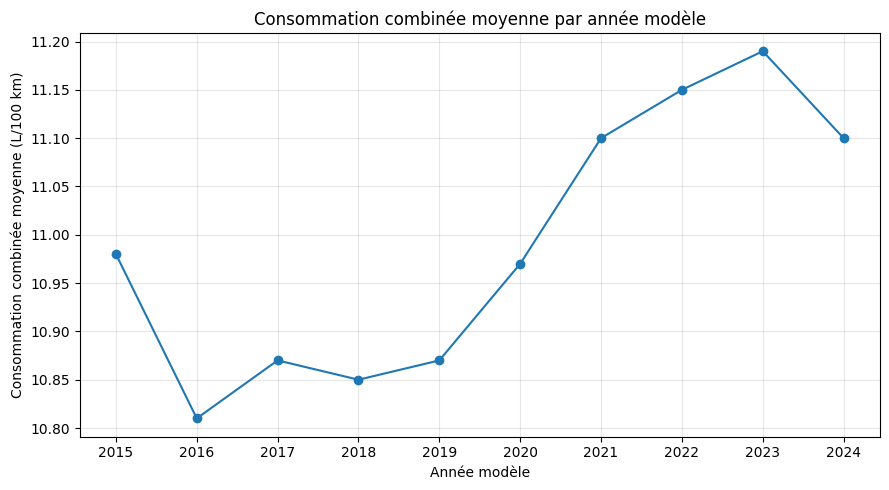

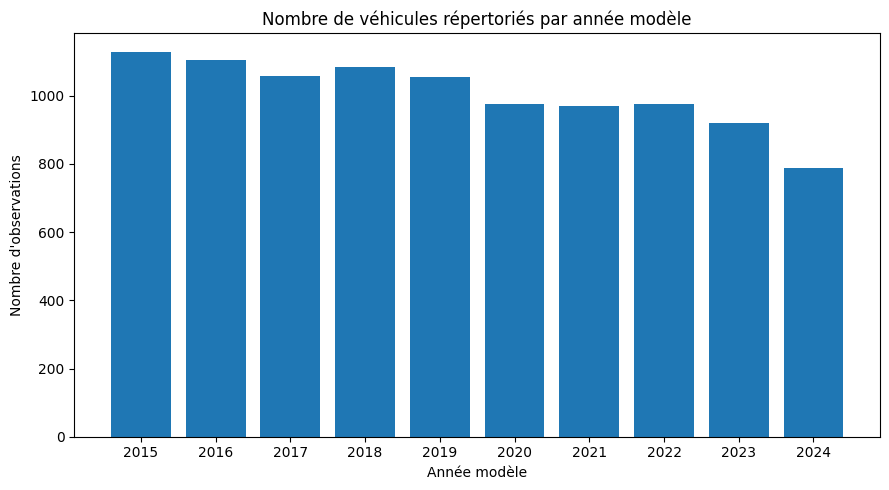

In [ ]:
# M013 - Évolution descriptive selon l'année modèle
# Objectif : Observer les tendances annuelles sans conclure à une causalité.
# Données : Aucune modification de df_analyse.

resume_annee = (
    df_analyse.groupby("Année modèle")
    .agg(
        Effectif=("Combinée (L/100 km)", "size"),
        Moyenne=("Combinée (L/100 km)", "mean"),
        Mediane=("Combinée (L/100 km)", "median"),
        Ecart_type=("Combinée (L/100 km)", "std"),
        CO2_moyen=("Émissions de CO2 (g/km)", "mean")
    )
    .round(2)
)

print("Résumé annuel :")
display(resume_annee)

# 1. Graphique de la consommation combinée moyenne.
plt.figure(figsize=(9, 5))
plt.plot(
    resume_annee.index,
    resume_annee["Moyenne"],
    marker="o"
)
plt.xlabel("Année modèle")
plt.ylabel("Consommation combinée moyenne (L/100 km)")
plt.title("Consommation combinée moyenne par année modèle")
plt.xticks(resume_annee.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Graphique des effectifs annuels.
plt.figure(figsize=(9, 5))
plt.bar(
    resume_annee.index.astype(str),
    resume_annee["Effectif"]
)
plt.xlabel("Année modèle")
plt.ylabel("Nombre d'observations")
plt.title("Nombre de véhicules répertoriés par année modèle")
plt.tight_layout()
plt.show()


In [ ]:
# M014 - Préparation des variables candidates
# Cible : Consommation combinée (L/100 km).
# Cette étape ne construit ni n'entraîne encore de modèle.

cible = "Combinée (L/100 km)"

variables_candidates = [
    "Année modèle",
    "Marque",
    "Modèle",
    "Catégorie de véhicule",
    "Cylindrée (L)",
    "Cylindres",
    "Transmission",
    "Type de carburant"
]

# Variables volontairement exclues du premier modèle :
#   - Ville (L/100 km)
#   - Route (L/100 km)
#   - Combinée (mi/gal)
#   - Émissions de CO2 (g/km)
# Ces mesures sont directement liées à la cible.

print("Variable cible :", cible)
print("\nVariables candidates :")
for variable in variables_candidates:
    print("-", variable, "| type :", df_analyse[variable].dtype,
          "| valeurs distinctes :", df_analyse[variable].nunique())

print("\nValeurs manquantes dans les variables candidates :")
display(df_analyse[variables_candidates].isna().sum().to_frame("Valeurs manquantes"))

print("\nValeurs manquantes dans la cible :",
      df_analyse[cible].isna().sum())


Variable cible : Combinée (L/100 km)

Variables candidates :
- Année modèle | type : int64 | valeurs distinctes : 10
- Marque | type : object | valeurs distinctes : 42
- Modèle | type : object | valeurs distinctes : 2080
- Catégorie de véhicule | type : object | valeurs distinctes : 16
- Cylindrée (L) | type : float64 | valeurs distinctes : 50
- Cylindres | type : int64 | valeurs distinctes : 8
- Transmission | type : object | valeurs distinctes : 28
- Type de carburant | type : object | valeurs distinctes : 5

Valeurs manquantes dans les variables candidates :


,Valeurs manquantes
Année modèle,0
Marque,0
Modèle,0
Catégorie de véhicule,0
Cylindrée (L),0
Cylindres,0
Transmission,0
Type de carburant,0



Valeurs manquantes dans la cible : 0


In [ ]:
# M015 - Premier essai de modélisation
# Objectif : Établir une référence et évaluer un modèle prédictif.
# Données : Les données originales et df_analyse ne sont pas modifiés.

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Définir la cible et les variables explicatives.
cible = "Combinée (L/100 km)"

variables_numeriques = [
    "Année modèle",
    "Cylindrée (L)",
    "Cylindres"
]

variables_categorielles = [
    "Catégorie de véhicule",
    "Transmission",
    "Type de carburant"
]

variables = variables_numeriques + variables_categorielles

X = df_analyse[variables].copy()
y = df_analyse[cible].copy()

# 2. Séparer les observations : 80 % entraînement, 20 % test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Observations d'entraînement :", len(X_train))
print("Observations de test :", len(X_test))

# 3. Préparer les variables numériques et catégorielles.
preparation = ColumnTransformer(
    transformers=[
        (
            "numeriques",
            SimpleImputer(strategy="median"),
            variables_numeriques
        ),
        (
            "categories",
            Pipeline([
                ("imputation", SimpleImputer(strategy="most_frequent")),
                ("encodage", OneHotEncoder(handle_unknown="ignore"))
            ]),
            variables_categorielles
        )
    ]
)

# 4. Modèle de référence : prédire la moyenne de l'entraînement.
modele_reference = DummyRegressor(strategy="mean")
modele_reference.fit(X_train, y_train)
pred_reference = modele_reference.predict(X_test)

# 5. Modèle de régression par forêt aléatoire.
modele_rf = Pipeline([
    ("preparation", preparation),
    ("modele", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

modele_rf.fit(X_train, y_train)
pred_rf = modele_rf.predict(X_test)

# 6. Comparer les performances sur les mêmes données de test.
def evaluer(nom, reel, predit):
    return {
        "Modèle": nom,
        "MAE (L/100 km)": mean_absolute_error(reel, predit),
        "RMSE (L/100 km)": np.sqrt(mean_squared_error(reel, predit)),
        "R²": r2_score(reel, predit)
    }

resultats = pd.DataFrame([
    evaluer("Référence (moyenne)", y_test, pred_reference),
    evaluer("Régression par forêt aléatoire", y_test, pred_rf)
]).set_index("Modèle").round(3)

print("\nRésultats sur l'ensemble de test :")
display(resultats)


Observations d'entraînement : 8048
Observations de test : 2012

Résultats sur l'ensemble de test :


,MAE (L/100 km),RMSE (L/100 km),R²
Modèle,,,
Référence (moyenne),2.196,2.782,-0.001
Régression par forêt aléatoire,0.497,0.725,0.932


In [ ]:
# M016 - Validation temporelle du modèle
# Objectif : Évaluer les prédictions sur des années absentes de l'entraînement.
# Données : Les données originales et df_analyse ne sont pas modifiés.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

cible = "Combinée (L/100 km)"

variables_numeriques = [
    "Année modèle",
    "Cylindrée (L)",
    "Cylindres"
]

variables_categorielles = [
    "Catégorie de véhicule",
    "Transmission",
    "Type de carburant"
]

variables = variables_numeriques + variables_categorielles

# Séparation chronologique : années récentes réservées au test.
entrainement = df_analyse["Année modèle"] <= 2022
test = df_analyse["Année modèle"].isin([2023, 2024])

X_train = df_analyse.loc[entrainement, variables].copy()
y_train = df_analyse.loc[entrainement, cible].copy()

X_test = df_analyse.loc[test, variables].copy()
y_test = df_analyse.loc[test, cible].copy()

print("Années d'entraînement :",
      sorted(df_analyse.loc[entrainement, "Année modèle"].unique()))
print("Années de test :",
      sorted(df_analyse.loc[test, "Année modèle"].unique()))
print("Observations d'entraînement :", len(X_train))
print("Observations de test :", len(X_test))

preparation_temporelle = ColumnTransformer(
    transformers=[
        (
            "numeriques",
            SimpleImputer(strategy="median"),
            variables_numeriques
        ),
        (
            "categories",
            Pipeline([
                ("imputation", SimpleImputer(strategy="most_frequent")),
                ("encodage", OneHotEncoder(handle_unknown="ignore"))
            ]),
            variables_categorielles
        )
    ]
)

# Modèle de référence.
reference_temporelle = DummyRegressor(strategy="mean")
reference_temporelle.fit(X_train, y_train)
pred_reference = reference_temporelle.predict(X_test)

# Modèle de régression par forêt aléatoire.
modele_temporel = Pipeline([
    ("preparation", preparation_temporelle),
    ("modele", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

modele_temporel.fit(X_train, y_train)
pred_rf = modele_temporel.predict(X_test)

def evaluer(nom, reel, predit):
    return {
        "Modèle": nom,
        "MAE (L/100 km)": mean_absolute_error(reel, predit),
        "RMSE (L/100 km)": np.sqrt(mean_squared_error(reel, predit)),
        "R²": r2_score(reel, predit)
    }

resultats_temporels = pd.DataFrame([
    evaluer("Référence (moyenne)", y_test, pred_reference),
    evaluer("Régression par forêt aléatoire", y_test, pred_rf)
]).set_index("Modèle").round(3)

print("\nRésultats de la validation temporelle :")
display(resultats_temporels)

print("\nConsommation réelle et prédite par année :")
comparaison = pd.DataFrame({
    "Année modèle": df_analyse.loc[test, "Année modèle"].values,
    "Consommation réelle": y_test.values,
    "Consommation prédite": pred_rf
})

display(
    comparaison.groupby("Année modèle")
    .agg(
        effectif=("Consommation réelle", "size"),
        moyenne_reelle=("Consommation réelle", "mean"),
        moyenne_predite=("Consommation prédite", "mean")
    )
    .round(3)
)


Années d'entraînement : [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]
Années de test : [np.int64(2023), np.int64(2024)]
Observations d'entraînement : 8352
Observations de test : 1708

Résultats de la validation temporelle :


,MAE (L/100 km),RMSE (L/100 km),R²
Modèle,,,
Référence (moyenne),2.227,2.84,-0.005
Régression par forêt aléatoire,0.610,0.91,0.897



Consommation réelle et prédite par année :


,effectif,moyenne_reelle,moyenne_predite
Année modèle,,,
2023,919,11.194,11.185
2024,789,11.099,11.097


In [ ]:
# M017 - Importance des variables dans le modèle de régression par forêt aléatoire
# Objectif : Identifier les variables les plus utilisées par le modèle.
# Cette analyse ne démontre pas de causalité.

noms_variables_transformees = (
    modele_temporel
    .named_steps["preparation"]
    .get_feature_names_out()
)

importances = (
    modele_temporel
    .named_steps["modele"]
    .feature_importances_
)

table_importance = pd.DataFrame({
    "Variable": noms_variables_transformees,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("Les 15 variables transformées les plus importantes :")
display(table_importance.head(15).round(4))

# Regrouper les importances par variable d'origine.
# Les catégories encodées en variables indicatrices sont additionnées.
def variable_origine(nom):
    if nom.startswith("numeriques__"):
        return nom.replace("numeriques__", "")
    if nom.startswith("categories__"):
        return nom.replace("categories__", "").split("_")[0]
    return nom

# Regroupement plus fiable à partir des préfixes des colonnes encodées.
noms_origine = []
for nom in noms_variables_transformees:
    if nom.startswith("numeriques__"):
        noms_origine.append(nom.replace("numeriques__", ""))
    elif nom.startswith("categories__"):
        nom_categorie = nom.replace("categories__", "")
        if nom_categorie.startswith("Catégorie de véhicule_"):
            noms_origine.append("Catégorie de véhicule")
        elif nom_categorie.startswith("Transmission_"):
            noms_origine.append("Transmission")
        elif nom_categorie.startswith("Type de carburant_"):
            noms_origine.append("Type de carburant")
        else:
            noms_origine.append(nom_categorie)
    else:
        noms_origine.append(nom)

importance_par_variable = (
    pd.DataFrame({
        "Variable d'origine": noms_origine,
        "Importance": importances
    })
    .groupby("Variable d'origine", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

print("\nImportance regroupée par variable d'origine :")
display(importance_par_variable.round(4))


Les 15 variables transformées les plus importantes :


,Variable,Importance
1,numeriques__Cylindrée (L),0.7443
48,categories__Type de carburant_E,0.0779
0,numeriques__Année modèle,0.0189
2,numeriques__Cylindres,0.0134
13,categories__Catégorie de véhicule_Intermédiaire,0.0126
28,categories__Transmission_AM7,0.0125
10,categories__Catégorie de véhicule_Fourgon : pa...,0.0124
16,categories__Catégorie de véhicule_Véhicule uti...,0.0120
38,categories__Transmission_AV,0.0107
51,categories__Type de carburant_Z,0.0088



Importance regroupée par variable d'origine :


,Variable d'origine,Importance
3,Cylindrée (L),0.7443
5,Type de carburant,0.0947
1,Catégorie de véhicule,0.0656
4,Transmission,0.0632
0,Année modèle,0.0189
2,Cylindres,0.0134


In [ ]:
# M018 - Importance des variables par permutation
# Objectif : Mesurer la perte de performance lorsqu'une variable
#            est mélangée dans l'ensemble de test temporel.
# Données : Aucune modification de df ou de df_analyse.

from sklearn.inspection import permutation_importance
import pandas as pd

importance_permutation = permutation_importance(
    modele_temporel,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

resultats_permutation = pd.DataFrame({
    "Variable": X_test.columns,
    "Augmentation moyenne du MAE": importance_permutation.importances_mean,
    "Écart-type": importance_permutation.importances_std
}).sort_values(
    "Augmentation moyenne du MAE",
    ascending=False
)

print("Importance par permutation sur les années 2023-2024 :")
display(resultats_permutation.round(4))


Importance par permutation sur les années 2023-2024 :


,Variable,Augmentation moyenne du MAE,Écart-type
1,Cylindrée (L),1.8118,0.0437
3,Catégorie de véhicule,0.3902,0.0103
4,Transmission,0.3886,0.0215
5,Type de carburant,0.2565,0.0078
2,Cylindres,0.0934,0.0057
0,Année modèle,-0.0000,0.0000


In [ ]:
# M019 - Comparaison avec une régression linéaire
# Objectif : Comparer un modèle simple au modèle de régression par forêt aléatoire.
#            Même ensemble d'entraînement et de test que M016.
# Données : Aucune modification des données originales.

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

modele_lineaire = Pipeline([
    ("preparation", preparation_temporelle),
    ("modele", LinearRegression())
])

modele_lineaire.fit(X_train, y_train)
pred_lineaire = modele_lineaire.predict(X_test)

resultats_comparaison = pd.DataFrame([
    {
        "Modèle": "Référence (moyenne)",
        "MAE (L/100 km)": mean_absolute_error(y_test, pred_reference),
        "RMSE (L/100 km)": np.sqrt(mean_squared_error(y_test, pred_reference)),
        "R²": r2_score(y_test, pred_reference)
    },
    {
        "Modèle": "Régression linéaire",
        "MAE (L/100 km)": mean_absolute_error(y_test, pred_lineaire),
        "RMSE (L/100 km)": np.sqrt(mean_squared_error(y_test, pred_lineaire)),
        "R²": r2_score(y_test, pred_lineaire)
    },
    {
        "Modèle": "Régression par forêt aléatoire",
        "MAE (L/100 km)": mean_absolute_error(y_test, pred_rf),
        "RMSE (L/100 km)": np.sqrt(mean_squared_error(y_test, pred_rf)),
        "R²": r2_score(y_test, pred_rf)
    }
]).set_index("Modèle").round(3)

print("Comparaison des modèles sur les années 2023–2024 :")
display(resultats_comparaison)


Comparaison des modèles sur les années 2023–2024 :


,MAE (L/100 km),RMSE (L/100 km),R²
Modèle,,,
Référence (moyenne),2.227,2.840,-0.005
Régression linéaire,0.958,1.287,0.793
Régression par forêt aléatoire,0.610,0.910,0.897
